In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.autograd import grad
import numpy as np
import matplotlib.pyplot as plt
from numpy import genfromtxt
torch.manual_seed(1234)
import os
import time

In [2]:
raw = np.genfromtxt(os.path.join("data", "bello_train.csv"),
                    delimiter=",")
t_data   = raw[0].astype(np.float32)
Itot_data = raw[1].astype(np.float32)
print(f"Data shape: t={len(t_data)}, Itot range [{Itot_data.min():.0f}, {Itot_data.max():.0f}]")

val_data = genfromtxt(os.path.join('data', 'bello_val.csv'), delimiter=',')
t_val = val_data[:, 0].astype(np.float32)
Itot_val = val_data[:, 1].astype(np.float32)
print(f"Validation data: t={len(t_val)}, Itot range {Itot_val.min():.0f}-{Itot_val.max():.0f}")

Data shape: t=80, Itot range [6, 1801]
Validation data: t=2, Itot range 82-1932


In [3]:
# Cell 1: FIXED - Imports, Data Load, Param Bounds, Model Definition, Inverse Training
# Parameter bounds [file:2]
param_bounds = {
    'lambda': (0.0, 0.6), 'betam': (0.0, 0.05), 'mum': (0.001, 0.016),
    'thetam': (0.01, 0.2), 'muh': (0.001, 0.0195), 'betah': (0.001, 0.055),
    'thetah': (0.01, 0.53), 'gammah': (0.05, 0.1)
}
calib_input_dim = 10

class CalibNet(nn.Module):
    def __init__(self, param_bounds):
        super().__init__()
        self.fc1 = nn.Linear(calib_input_dim, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, len(param_bounds))
        self.param_bounds = param_bounds
        self.param_names = list(param_bounds.keys())

    def forward(self, calib_input):
        x = F.gelu(self.fc1(calib_input))
        x = F.gelu(self.fc2(x))
        raw = self.fc3(x)
        params = {}
        for i, name in enumerate(self.param_names):
            lo, hi = self.param_bounds[name]
            p_tilda = raw[..., i]
            p = torch.tanh(p_tilda) * (hi - lo)/2 + (hi + lo)/2
            params[name] = p
        return params

class EmuNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(1, 20); self.fc2 = nn.Linear(20, 20); self.fc3 = nn.Linear(20, 20)
        self.fc4 = nn.Linear(20, 20); self.fc5 = nn.Linear(20, 20); self.fc6 = nn.Linear(20, 20)
        self.fc7 = nn.Linear(20, 20); self.fc8 = nn.Linear(20, 20); self.out = nn.Linear(20, 8)

    def forward(self, t_batch):
        x = F.gelu(self.fc1(t_batch)); x = F.gelu(self.fc2(x)); x = F.gelu(self.fc3(x))
        x = F.gelu(self.fc4(x)); x = F.gelu(self.fc5(x)); x = F.gelu(self.fc6(x))
        x = F.gelu(self.fc7(x)); x = F.gelu(self.fc8(x))
        return F.softplus(self.out(x))

class DengueDINN2(nn.Module):
    def __init__(self, t, Itot_data, param_bounds):
        super().__init__()
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.t = torch.tensor(t, dtype=torch.float32,
                              requires_grad=True, device=self.device)
        self.t_batch = self.t.reshape(-1, 1)
        self.Itot = torch.tensor(Itot_data, dtype=torch.float32,
                                     device=self.device)
        self.Itot_hat = torch.log1p(self.Itot)
        self.calib = CalibNet(param_bounds).to(self.device)
        self.emu   = EmuNet().to(self.device)
        self.params = list(self.calib.parameters()) + list(self.emu.parameters())
        self.optimizer = optim.Adam(
            self.params,
            lr=5e-4,
            betas=(0.9, 0.999),
            weight_decay=1e-5
        )
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer,
            mode='min',
            factor=0.7,
            patience=1000,
            min_lr=1e-7
        )
        self.losses = []


    def netf(self, calib_input):
        calib_input = calib_input.to(self.device)
        params = self.calib(calib_input)
        λ = params['lambda']; betam = params['betam']; mum = params['mum']; thetam = params['thetam']
        muh = params['muh']; betah = params['betah']; thetah = params['thetah']; gammah = params['gammah']
        dengue_hat = self.emu(self.t_batch)
        Hr_hat = dengue_hat[:, 0:1]; Hs_hat = dengue_hat[:, 1:2]; He_hat = dengue_hat[:, 2:3]
        Hi_hat = dengue_hat[:, 3:4]; Me_hat = dengue_hat[:, 4:5]; Ms_hat = dengue_hat[:, 5:6]
        Mi_hat = dengue_hat[:, 6:7]; Itot_hat_pred = dengue_hat[:, 7:8]
        # FIXED: Correct grad_outputs shape [N,1] matching output shape
        Hr_t = grad(Hr_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Hs_t = grad(Hs_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        He_t = grad(He_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Hi_t = grad(Hi_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Me_t = grad(Me_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Ms_t = grad(Ms_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Mi_t = grad(Mi_hat.sum(), self.t, retain_graph=True, create_graph=True)[0]
        Itot_t = grad(Itot_hat_pred.sum(), self.t, retain_graph=True, create_graph=True)[0]
        # Unnormalize
        Hr = torch.expm1(Hr_hat.squeeze(1)); Hs = torch.expm1(Hs_hat.squeeze(1))
        He = torch.expm1(He_hat.squeeze(1)); Hi = torch.expm1(Hi_hat.squeeze(1))
        Me = torch.expm1(Me_hat.squeeze(1)); Ms = torch.expm1(Ms_hat.squeeze(1))
        Mi = torch.expm1(Mi_hat.squeeze(1)); Itot = torch.expm1(Itot_hat_pred.squeeze(1))
        H = torch.clamp(Hr + Hs + He + Hi, min=1e-8)
        M = torch.clamp(Me + Ms + Mi, min=1e-8)
        # Residuals
        f1_hat = Hr_t - (gammah * Hi - muh * Hr) / (1.0 + Hr)
        f2_hat = Hs_t - (muh * H - betah * Mi * Hs / M - muh * Hs) / (1.0 + Hs)
        f3_hat = He_t - (betah * Mi * Hs / M - thetah * He - muh * He) / (1.0 + He)
        f4_hat = Hi_t - (thetah * He - gammah * Hi - muh * Hi) / (1.0 + Hi)
        f5_hat = Me_t - (betam * Hi * Ms / H - thetam * Me - mum * Me) / (1.0 + Me)
        f6_hat = Ms_t - (λ - betam * Hi * Ms / H - mum * Ms) / (1.0 + Ms)
        f7_hat = Mi_t - (thetam * Me - mum * Mi) / (1.0 + Mi)
        f8_hat = Itot_t - (thetah * He) / (1.0 + Itot)
        return (f1_hat, f2_hat, f3_hat, f4_hat, f5_hat, f6_hat, f7_hat, f8_hat, Itot_hat_pred.squeeze(1))

    def train_loop(self, nepochs=2000):
        calib_input = torch.zeros(1, calib_input_dim)
        start_time = time.time() 
        self.loss_data_list = []
        self.loss_phys_list = []
        for epoch in range(nepochs):
            self.optimizer.zero_grad()
            f = self.netf(calib_input)
            loss_data = F.mse_loss(f[8], self.Itot_hat)
            loss_phys = sum(F.mse_loss(r, torch.zeros_like(r)) for r in f[:8])
            loss = loss_data + loss_phys
            loss.backward()
            self.optimizer.step()
            self.scheduler.step(loss.detach())
            self.losses.append(loss.item())
            self.loss_data_list.append(loss_data.item())
            self.loss_phys_list.append(loss_phys.item())
            if epoch % 200 == 0:
                print(f"Epoch {epoch}: Total loss: {loss.item():.2e}, data loss: {loss_data.item():.2e}, physic loss: {loss_phys.item():.2e}")
        end_time = time.time()
        runtime = end_time - start_time
        print(f"Training completed in {runtime:.2f} seconds ({runtime/60:.2f} minutes)")
        
        # Plot
        plt.figure(figsize=(10,6))
        plt.semilogy(self.losses, label='Total loss', linewidth=2)
        plt.semilogy(self.loss_data_list, label='Data loss', linewidth=2)
        plt.semilogy(self.loss_phys_list, label='Physics loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Training Losses')
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()
        print("Inverse training complete")


Epoch 0: Total loss: 2.75e+01, data loss: 2.74e+01, physic loss: 7.69e-02
Epoch 200: Total loss: 9.32e-01, data loss: 9.21e-01, physic loss: 1.10e-02
Epoch 400: Total loss: 1.55e-01, data loss: 1.46e-01, physic loss: 9.59e-03
Epoch 600: Total loss: 2.47e-02, data loss: 1.58e-02, physic loss: 8.93e-03
Epoch 800: Total loss: 1.39e-02, data loss: 5.35e-03, physic loss: 8.53e-03
Epoch 1000: Total loss: 1.26e-02, data loss: 4.49e-03, physic loss: 8.10e-03
Epoch 1200: Total loss: 1.22e-02, data loss: 4.43e-03, physic loss: 7.82e-03
Epoch 1400: Total loss: 1.21e-02, data loss: 4.42e-03, physic loss: 7.64e-03
Epoch 1600: Total loss: 1.19e-02, data loss: 4.40e-03, physic loss: 7.51e-03
Epoch 1800: Total loss: 1.18e-02, data loss: 4.37e-03, physic loss: 7.39e-03
Epoch 2000: Total loss: 1.16e-02, data loss: 4.33e-03, physic loss: 7.28e-03
Epoch 2200: Total loss: 1.14e-02, data loss: 4.26e-03, physic loss: 7.17e-03
Epoch 2400: Total loss: 1.12e-02, data loss: 4.18e-03, physic loss: 7.04e-03
Epoch 

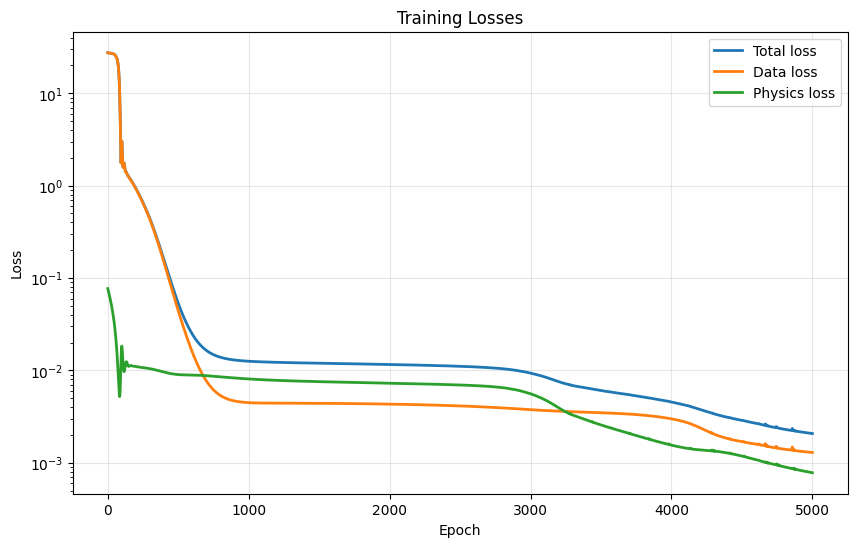

Inverse training complete


In [4]:
# Instantiate & Train
dinn2 = DengueDINN2(t_data, Itot_data, param_bounds)
dinn2.train_loop(5001)

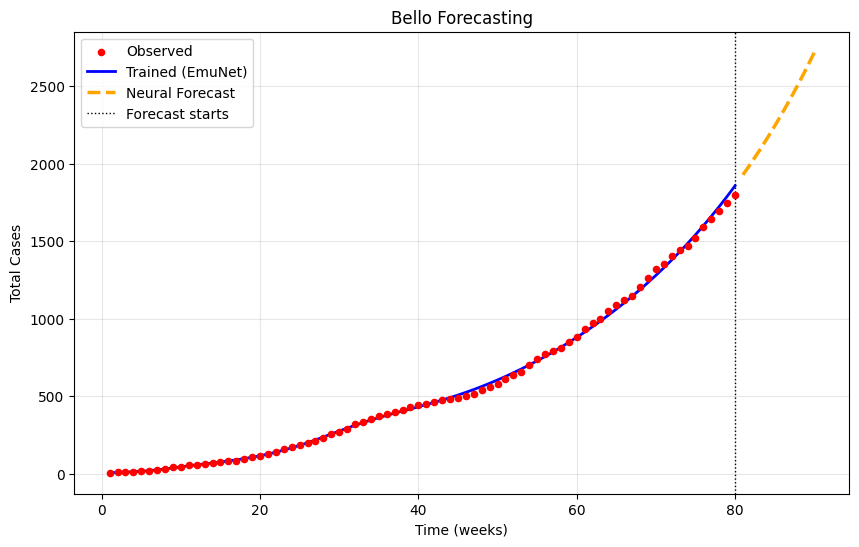

In [5]:
# Cell 2: Pure Neural Forecasting (EmuNet extrapolation)
forecast_weeks = 10
t_last = float(t_data[-1])
t_forecast = np.linspace(t_last, t_last + forecast_weeks, forecast_weeks + 1)[1:]
t_forecast_tensor = torch.tensor(t_forecast).float().reshape(-1, 1)

dinn2.eval()
with torch.no_grad():
    states_log_forecast = dinn2.emu(t_forecast_tensor)
    Itot_neural_forecast = torch.expm1(states_log_forecast[:, 7]).numpy()

# Plot
plt.figure(figsize=(10,6))
plt.scatter(t_data, Itot_data, s=20, color='red', label='Observed', zorder=5)
train_Itot = torch.expm1(dinn2.emu(dinn2.t_batch)[:, 7]).detach().numpy()
plt.plot(dinn2.t.detach().numpy(), train_Itot, 'b-', lw=2, label='Trained (EmuNet)')
plt.plot(t_forecast, Itot_neural_forecast, 'orange', ls='--', lw=2.5, label='Neural Forecast')
plt.axvline(t_last, color='k', ls=':', lw=1, label='Forecast starts')
plt.xlabel('Time (weeks)'); plt.ylabel('Total Cases'); plt.legend(); plt.grid(True, alpha=0.3)
plt.title('Bello Forecasting')
plt.show()
# print(f"Neural forecast final value: {Itot_neural_forecast[-1]:.1f}")


In [6]:
# Cell 3: Relative RMSE (NRMSE / std normalization) for Itot
import math

dengue_data = [t_data, Itot_data]  # weeks, cumulative Hi
with torch.no_grad():
    Itot_hat_pred = dinn2.emu(dinn2.t_batch)[:, 7]  # log1p from emu
    Itot_pred = torch.expm1(Itot_hat_pred).cpu().numpy()  # denormalize

Itot_total_loss = 0 
Itot_den = 0
for timestep in range(len(dengue_data[0])):
    Itot_value = dengue_data[1][timestep] - Itot_pred[timestep]
    Itot_total_loss += Itot_value**2
    Itot_den += (dengue_data[1][timestep])**2

Itot_total_loss = math.sqrt(Itot_total_loss / Itot_den)
print('Itot_total_loss (relative RMSE):', Itot_total_loss)


Itot_total_loss (relative RMSE): 0.02034727410262262


MAE weeks 81-90: 249 cases
RMSE weeks 81-90: 296 cases

Checking physics residuals...
Physics residuals (mean abs):
  f1: 4.72e-03
  f2: 1.16e-02
  f3: 5.01e-03
  f4: 4.14e-03
  f5: 3.67e-03
  f6: 1.69e-03
  f7: 5.16e-03
  f8: 1.70e-02


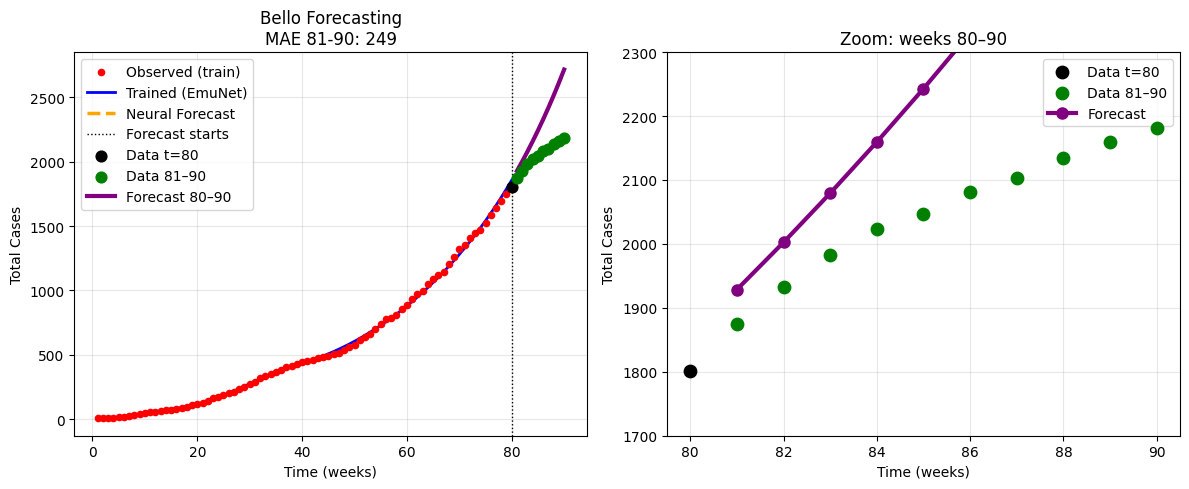


✅ Hoàn chỉnh! Kiểm tra residuals để debug physics loss.


In [10]:
# Cell 2: FULL FIXED - Better forecasting + metrics (NO GRAD ERROR)
import numpy as np
import matplotlib.pyplot as plt
from numpy import genfromtxt
import torch.nn.functional as F

# ================== LOAD & FORECAST ==================
forecast_weeks = 10
t_last = float(t_data[-1])
t_forecast = np.linspace(t_last, t_last + forecast_weeks, forecast_weeks + 1)[1:]
t_forecast_tensor = torch.tensor(t_forecast).float().reshape(-1, 1)

dinn2.eval()
with torch.no_grad():
    states_log_forecast = dinn2.emu(t_forecast_tensor)
    Itot_neural_forecast = torch.expm1(states_log_forecast[:, 7]).cpu().numpy()

# FIXED: Parse val.csv đúng (2 rows)
val_raw = genfromtxt('data/bello_val.csv', delimiter=',')
t_val = val_raw[0, :].astype(np.float32)
Itot_val = val_raw[1, :].astype(np.float32)

# Tuần 80 từ train
mask_t80 = (t_data == 80)
t_80 = t_data[mask_t80]
Itot_80 = Itot_data[mask_t80]

# Tuần 81–90 từ val
t_val_81_90 = t_val[(t_val >= 81) & (t_val <= 90)]
Itot_val_81_90 = Itot_val[(t_val >= 81) & (t_val <= 90)]

# Forecast 80–90
mask_forecast_80_90 = (t_forecast >= 80) & (t_forecast <= 90)
t_forecast_80_90 = t_forecast[mask_forecast_80_90]
Itot_forecast_80_90 = Itot_neural_forecast[mask_forecast_80_90]

# ================== METRICS ==================
mask_val = (t_forecast >= 81) & (t_forecast <= 90)
mae_81_90 = np.mean(np.abs(Itot_neural_forecast[mask_val] - Itot_val_81_90))
rmse_81_90 = np.sqrt(np.mean((Itot_neural_forecast[mask_val] - Itot_val_81_90)**2))
print(f"MAE weeks 81-90: {mae_81_90:.0f} cases")
print(f"RMSE weeks 81-90: {rmse_81_90:.0f} cases")

# ================== PHYSICS RESIDUALS (KHÔNG dùng no_grad) ==================
print("\nChecking physics residuals...")
calib_input = torch.zeros(1, 10).to(dinn2.device)
f = dinn2.netf(calib_input)  # Bỏ no_grad để tính grad
residual_means = [f[i].abs().mean().item() for i in range(8)]
print("Physics residuals (mean abs):")
for i, res in enumerate(residual_means):
    print(f"  f{i+1}: {res:.2e}")

# ================== PLOTS ==================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Full view
ax1.scatter(t_data, Itot_data, s=20, color='red', label='Observed (train)', zorder=5)
train_Itot = torch.expm1(dinn2.emu(dinn2.t_batch)[:, 7]).detach().cpu().numpy()
ax1.plot(dinn2.t.detach().cpu().numpy(), train_Itot, 'b-', lw=2, label='Trained (EmuNet)')
ax1.plot(t_forecast, Itot_neural_forecast, 'orange', ls='--', lw=2.5, label='Neural Forecast')
ax1.axvline(t_last, color='k', ls=':', lw=1, label='Forecast starts')
ax1.scatter(t_80, Itot_80, color='black', s=60, label='Data t=80', zorder=6)
ax1.scatter(t_val_81_90, Itot_val_81_90, color='green', s=60, label='Data 81–90', zorder=6)
ax1.plot(t_forecast_80_90, Itot_forecast_80_90, color='purple', lw=3, label='Forecast 80–90')
ax1.set_xlabel('Time (weeks)'); ax1.set_ylabel('Total Cases')
ax1.set_title(f'Bello Forecasting\nMAE 81-90: {mae_81_90:.0f}')
ax1.legend(); ax1.grid(True, alpha=0.3)

# Zoom 80-90
ax2.scatter(t_80, Itot_80, color='black', s=80, label='Data t=80', zorder=6)
ax2.scatter(t_val_81_90, Itot_val_81_90, color='green', s=80, label='Data 81–90', zorder=6)
ax2.plot(t_forecast_80_90, Itot_forecast_80_90, color='purple', lw=3, label='Forecast', marker='o', markersize=8)
ax2.set_xlim(79.5, 90.5); ax2.set_ylim(1700, 2300)
ax2.set_xlabel('Time (weeks)'); ax2.set_ylabel('Total Cases')
ax2.set_title('Zoom: weeks 80–90')
ax2.legend(); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✅ Hoàn chỉnh! Kiểm tra residuals để debug physics loss.")
